### 1. Deskripsi Dataset & Identifikasi Variabel
Dataset ini berisi informasi tentang penerima asuransi kesehatan:
- **Variabel Bebas (X)**:
  - `age`: Umur pasien
  - `sex`: Jenis kelamin (female / male)
  - `bmi`: Indeks massa tubuh
  - `children`: Jumlah anak/tanggungan
  - `smoker`: Status merokok (yes / no)
  - `region`: Wilayah domisili (northeast, northwest, southeast, southwest)
- **Variabel Target (y)**:
  - `charges`: Biaya medis personal yang ditagih asuransi

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# baca data
data = pd.read_csv('insurance.csv')
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
# cek info dan ukuran data
print(data.info())
print(data.describe())

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB
None
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
max      64.000000

### 2. Visualisasi Data

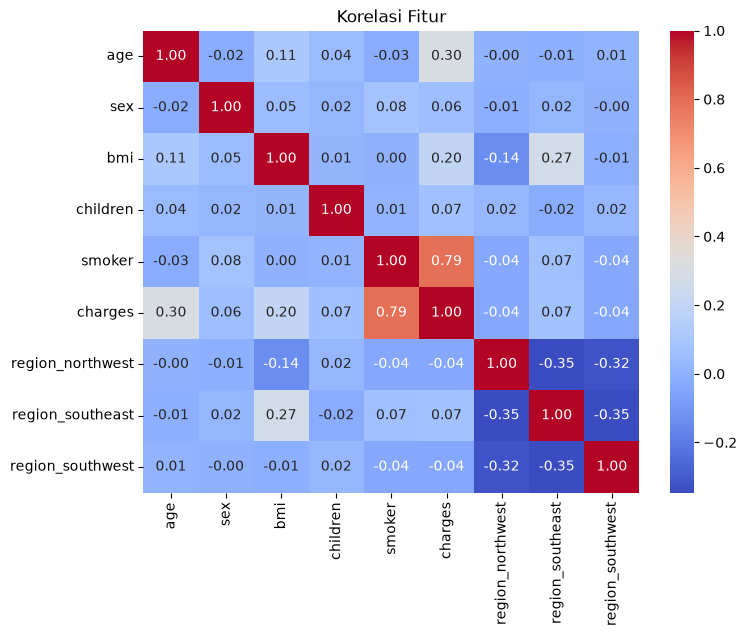

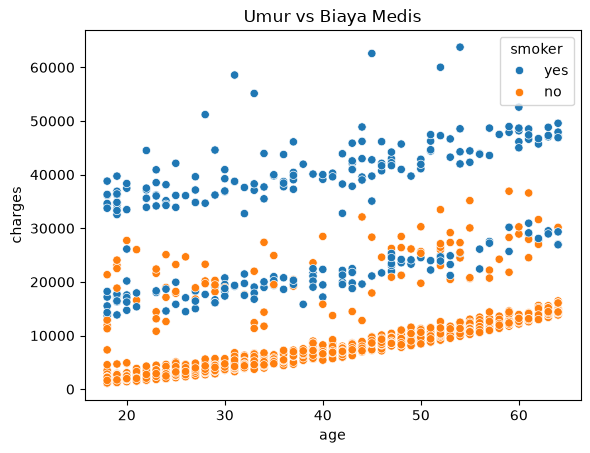

In [3]:
# encoding variabel kategorik untuk cek korelasi
df = data.copy()
df['sex'] = df['sex'].map({'female': 0, 'male': 1})
df['smoker'] = df['smoker'].map({'no': 0, 'yes': 1})
df = pd.get_dummies(df, columns=['region'], drop_first=True, dtype=int)

# heatmap korelasi
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Korelasi Fitur')
plt.show()

# scatter plot umur vs charges
sns.scatterplot(x='age', y='charges', hue='smoker', data=data)
plt.title('Umur vs Biaya Medis')
plt.show()

### 3. Pemisahan Fitur dan Target & Train-Test Split

In [4]:
from sklearn.model_selection import train_test_split

X = df.drop('charges', axis=1)
y = df['charges']

# bagi data 80% train dan 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji  :", len(X_test))

Jumlah data latih: 1070
Jumlah data uji  : 268


### 4. Feature Scaling

In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 5. Training Multiple Linear Regression

In [6]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_scaled, y_train)

# prediksi data uji
y_pred = model.predict(X_test_scaled)

# koefisien tiap fitur
koefisien = pd.DataFrame({'Fitur': X.columns, 'Koefisien': model.coef_})
koefisien

,Fitur,Koefisien
0,age,3614.975415
1,sex,-9.293101
2,bmi,2036.228123
3,children,516.890247
4,smoker,9558.481409
5,region_northwest,-158.140981
6,region_southeast,-290.157047
7,region_southwest,-349.110678


### 6. Evaluasi Model

In [7]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("R-squared :", r2)
print("MAE       :", mae)
print("MSE       :", mse)
print("RMSE      :", rmse)

R-squared : 0.7835929767120722
MAE       : 4181.1944737536505
MSE       : 33596915.851361476
RMSE      : 5796.284659276274


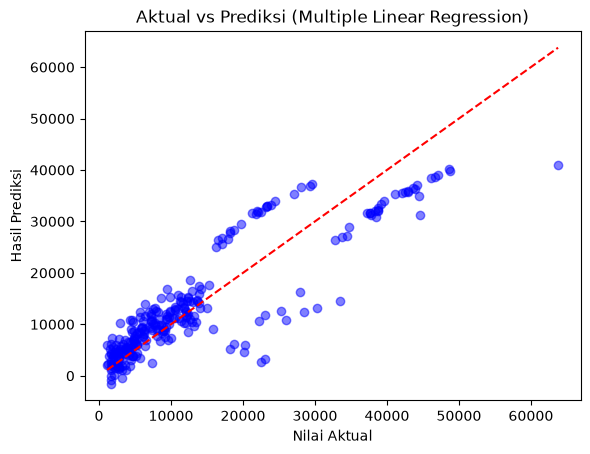

In [8]:
# visualisasi nilai asli vs hasil prediksi
plt.scatter(y_test, y_pred, color='blue', alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Nilai Aktual')
plt.ylabel('Hasil Prediksi')
plt.title('Aktual vs Prediksi (Multiple Linear Regression)')
plt.show()

### Analisis Hasil:
1. **Faktor paling berpengaruh**: Dari matriks korelasi dan nilai koefisien regresi, status merokok (`smoker`) memiliki pengaruh paling besar terhadap biaya medis. Orang yang merokok membayar biaya asuransi yang jauh lebih tinggi dibanding non-perokok.
2. **Pengaruh umur dan BMI**: Variabel `age` dan `bmi` juga berpengaruh positif terhadap biaya medis; semakin bertambah umur atau semakin tinggi BMI, biaya medis yang dikeluarkan cenderung meningkat.
3. **Kinerja Model**: Model Multiple Linear Regression mendapatkan skor R-squared sebesar **0.7836**. Ini berarti sekitar 78.4% variasi biaya medis berhasil diprediksi dengan baik oleh fitur-fitur yang ada. Nilai MAE sebesar 4181.19 menunjukkan rata-rata selisih prediksi dengan biaya aslinya.